# [GSE126468](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE126468)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-03-16
> - Modified: 2025-05-05

# 1. Experimental Design

> The chromosomal protein SMCHD1 regulates DNA methylation by antagonizing TET proteins.
> - Zhijun Huang et al. ,The chromosomal protein SMCHD1 regulates DNA methylation and the 2c-like state of embryonic stem cells by antagonizing TET proteins.Sci. Adv.7,eabb9149(2021).DOI:10.1126/sciadv.abb9149.
> - Swift, Accel-NGS Methyl-Seq DNA Library Kit (Swift Biosciences, 30024), and Zymo’s EZ DNA Methylation-Lightning kit (Zymo Research, D5030)
> - Illumina HiSeq X Ten, PE150
> - Bismark-Bowtie2
> - mm9


| Sample | Cell | Organism | Strain | Tissue | Genotype | Replicate |
| - | - | - | - | - | - | - |
| WT | mESC | Mus musculus | J1 | Embryonic stem cells | Wild Type | rep1~3 |
| KO | mESC | Mus musculus | J1 | Embryonic stem cells | Smchd1 KO | rep1~3 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/wgbs_Mm_mESC_Smchd1_GSE126468"

In [3]:
file_pattern <- "^GSM\\d+_(.*)\\.bismark\\.cov\\.gz$"

cov_files <- file.path(data_dir, "00_geo") |>
    list.files(pattern = file_pattern, full.names = TRUE) |>
    set_names(~ sub(file_pattern, "\\1", basename(.x)))

paste(names(cov_files), basename(cov_files), sep = ": ") |> cat(sep = "\n")

mESC_Smchd1_WT_rep1: GSM3602177_mESC_Smchd1_WT_rep1.bismark.cov.gz
mESC_Smchd1_WT_rep2: GSM3602178_mESC_Smchd1_WT_rep2.bismark.cov.gz
mESC_Smchd1_WT_rep3: GSM3602179_mESC_Smchd1_WT_rep3.bismark.cov.gz
mESC_Smchd1_KO_rep1: GSM3602180_mESC_Smchd1_KO_rep1.bismark.cov.gz
mESC_Smchd1_KO_rep2: GSM3602181_mESC_Smchd1_KO_rep2.bismark.cov.gz
mESC_Smchd1_KO_rep3: GSM3602182_mESC_Smchd1_KO_rep3.bismark.cov.gz


In [4]:
coldata <- data.frame(sample = names(cov_files)) |>
    separate(
        sample, into = c("Cell", "Gene", "Group", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("WT", "KO")),
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
mESC_Smchd1_WT_rep1,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep2,mESC,Smchd1,WT,rep2
mESC_Smchd1_WT_rep3,mESC,Smchd1,WT,rep3
mESC_Smchd1_KO_rep1,mESC,Smchd1,KO,rep1
mESC_Smchd1_KO_rep2,mESC,Smchd1,KO,rep2
mESC_Smchd1_KO_rep3,mESC,Smchd1,KO,rep3


In [5]:
suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm9))
genome <- BSgenome.Mmusculus.UCSC.mm9

suppressPackageStartupMessages(library(TxDb.Mmusculus.UCSC.mm9.knownGene))
txdb <- TxDb.Mmusculus.UCSC.mm9.knownGene

# 5. DMRs

> - DMRs: bsseq
> - DMLs-based approaches: DSS, DMRcate
> - Tiling windows approaches: methylKit
> - Predefined regions of the genome (Promoter, Enhancer, Gene body, CGI etc.): methylKit

## 1). [bsseq](https://www.bioconductor.org/packages/release/bioc/html/bsseq.html)

> BSmooth algorithm
> 
> Notes:
>   - Recommend using the ’genome wide cytosine report’ output format because it includes strand information for each locus.

```shell
zless ${prefix}.CpG_report.txt.gz | head
chr1	10469	+	1	0	CG	CGC
chr1	10470	-	2	5	CG	CGA
chr1	10471	+	1	0	CG	CGG
chr1	10472	-	3	2	CG	CGC
chr1	10484	+	1	0	CG	CGG
chr1	10485	-	4	0	CG	CGG
```

In [6]:
suppressPackageStartupMessages(library(bsseq))
# suppressPackageStartupMessages(library(HDF5Array))
suppressPackageStartupMessages(library(BiocParallel))

### a). Preprocessing

In [7]:
# CpG <- Biostrings::vmatchPattern("CG", genome) |>
#     GenomeInfoDb::keepStandardChromosomes(pruning.mode = "coarse") |>
#     GenomeInfoDb::dropSeqlevels("chrM", pruning.mode = "coarse")
CpG <- bsseq::findLoci("CG", genome) |>
    GenomeInfoDb::keepStandardChromosomes(pruning.mode = "coarse") |>
    GenomeInfoDb::dropSeqlevels("chrM", pruning.mode = "coarse")
CpG

GRanges object with 42684984 ranges and 0 metadata columns:
             seqnames    ranges strand
                <Rle> <IRanges>  <Rle>
         [1]     chr1   3000574      +
         [2]     chr1   3000726      +
         [3]     chr1   3000901      +
         [4]     chr1   3001346      +
         [5]     chr1   3001394      +
         ...      ...       ...    ...
  [42684980]     chrY   2901855      -
  [42684981]     chrY   2902115      -
  [42684982]     chrY   2902430      -
  [42684983]     chrY   2902454      -
  [42684984]     chrY   2902492      -
  -------
  seqinfo: 21 sequences from mm9 genome

In [8]:
# ~ 1 min
bs_obj <- read.bismark(
    files = cov_files, loci = CpG, colData = coldata, 
    rmZeroCov = FALSE, strandCollapse = TRUE)

bs_obj

# bs_obj <- bsseq::BSseq(
#     chr = seqnames(gr), pos = start(gr), 
#     M = matrix(gr$numCs, ncol = 1),
#     Cov = matrix(gr$numCs + gr$numTs, ncol = 1), 
#     sampleNames = sample_id)

An object of type 'BSseq' with
  21342492 methylation loci
  6 samples
has not been smoothed
All assays are in-memory

In [9]:
granges(bs_obj)

GRanges object with 21342492 ranges and 0 metadata columns:
             seqnames    ranges strand
                <Rle> <IRanges>  <Rle>
         [1]     chr1   3000574      *
         [2]     chr1   3000726      *
         [3]     chr1   3000901      *
         [4]     chr1   3001346      *
         [5]     chr1   3001394      *
         ...      ...       ...    ...
  [21342488]     chrY   2901854      *
  [21342489]     chrY   2902114      *
  [21342490]     chrY   2902429      *
  [21342491]     chrY   2902453      *
  [21342492]     chrY   2902491      *
  -------
  seqinfo: 21 sequences from mm9 genome

In [10]:
getCoverage(bs_obj, type = "M") |> head()

mESC_Smchd1_WT_rep1,mESC_Smchd1_WT_rep2,mESC_Smchd1_WT_rep3,mESC_Smchd1_KO_rep1,mESC_Smchd1_KO_rep2,mESC_Smchd1_KO_rep3
7,9,8,6,9,7
3,2,5,5,5,5
0,0,0,0,0,0
4,2,2,1,2,1
5,4,4,1,4,2
25,20,21,15,18,15


In [11]:
sampleNames(bs_obj)

pData(bs_obj)

[1] "mESC_Smchd1_WT_rep1" "mESC_Smchd1_WT_rep2" "mESC_Smchd1_WT_rep3"
[4] "mESC_Smchd1_KO_rep1" "mESC_Smchd1_KO_rep2" "mESC_Smchd1_KO_rep3"

DataFrame with 6 rows and 4 columns
                           Cell        Gene    Group Replicate
                    <character> <character> <factor>  <factor>
mESC_Smchd1_WT_rep1        mESC      Smchd1       WT      rep1
mESC_Smchd1_WT_rep2        mESC      Smchd1       WT      rep2
mESC_Smchd1_WT_rep3        mESC      Smchd1       WT      rep3
mESC_Smchd1_KO_rep1        mESC      Smchd1       KO      rep1
mESC_Smchd1_KO_rep2        mESC      Smchd1       KO      rep2
mESC_Smchd1_KO_rep3        mESC      Smchd1       KO      rep3

### b). BSmooth Algorithm

In [ ]:
# Extreme memory consumption
# ~ 60 min, Threads: 2, memory: 24G
# ~ 35 min, Threads: 4, memory: 36G
bs_obj_fit <- BSmooth(
    BSseq = bs_obj, 
    BPPARAM = MulticoreParam(workers = 4))
# Warning from ZeroMQ!!!
bs_obj_fit

R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_ms

An object of type 'BSseq' with
  21342492 methylation loci
  6 samples
has been smoothed with
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
All assays are in-memory

In [13]:
bs_obj_fit_cov <- getCoverage(bs_obj_fit)

keep_idx <- which(
    rowSums(bs_obj_fit_cov[
        , bs_obj_fit$Group == "KO", drop = FALSE] >= 5) >= 2 & 
    rowSums(bs_obj_fit_cov[
        , bs_obj_fit$Group == "WT", drop = FALSE] >= 5) >= 2
)

cat("Number of loci kept after filtering:", length(keep_idx), "\n")

Number of loci kept after filtering: 16365416 


In [14]:
bs_obj_filter <- bs_obj_fit[keep_idx, ]

bs_obj_filter

An object of type 'BSseq' with
  16365416 methylation loci
  6 samples
has been smoothed with
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
All assays are in-memory

### c). DMRs

In [15]:
# ~ 1 min
bs_obj_tstat <- BSmooth.tstat(
    bs_obj_filter, group1 = 4:6, group2 = 1:3, 
    estimate.var = "group2", local.correct = TRUE)

bs_obj_tstat

[BSmooth.tstat] preprocessing ... 

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 16365416 out-of-bound ranges located on sequences
  chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12,
  chr13, chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that
  ranges located on a sequence whose length is unknown (NA) or on a circular
  sequence are not considered out-of-bound (use seqlengths() and isCircular()
  to get the lengths and circularity flags of the underlying sequences). You
  can use trim() to trim these ranges. See ?`trim,GenomicRanges-method` for
  more information.”
Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 21 out-of-bound ranges located on sequences chr1,
  chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13,
  chr14, chr15, chr16, chr17, chr18, chr19, chrX, and chrY. Note that ranges
  located on a sequence whose length is unknown (NA) or on a circula

done in 4.8 sec
[BSmooth.tstat] computing stats within groups ... done in 2.8 sec
[BSmooth.tstat] computing stats across groups ... done in 31.2 sec


An object of type 'BSseqTstat' with
  16365416 methylation loci
based on smoothed data:
  BSmooth (ns = 70, h = 1000, maxGap = 100000000) 
with parameters
  BSmooth.tstat (local.correct = TRUE, maxGap = 100000000) 

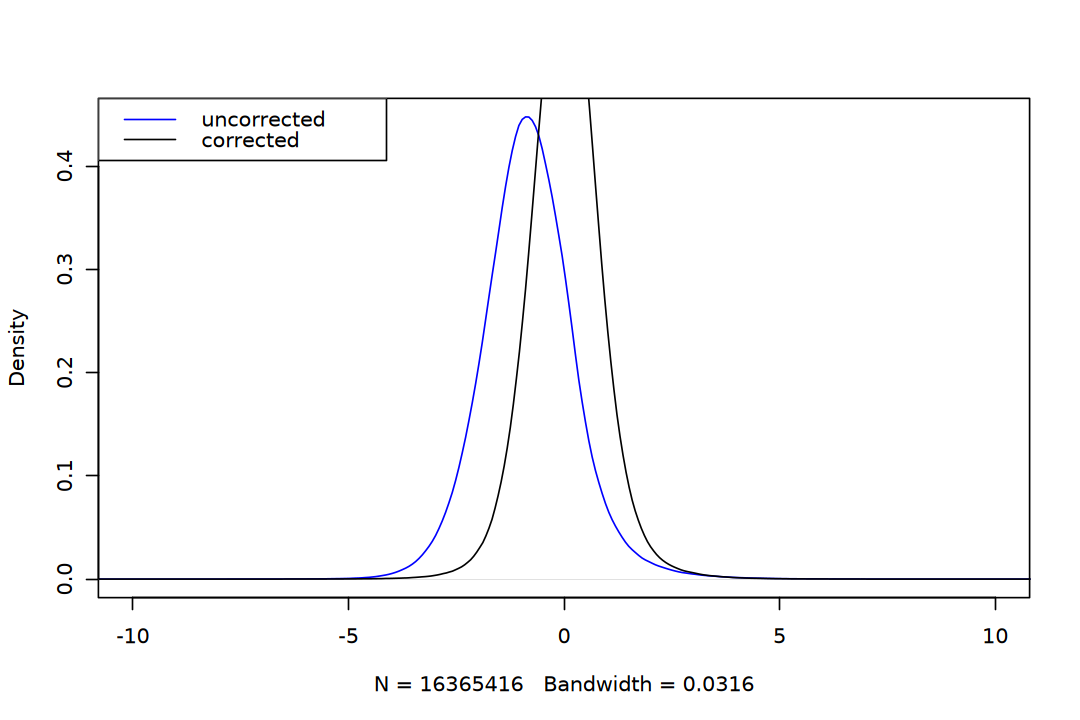

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(bs_obj_tstat)

In [17]:
bsseq_dmrs <- dmrFinder(bs_obj_tstat, cutoff = c(-4.6, 4.6)) |>
    subset(n >= 10 & abs(meanDiff) >= 0.1)

[dmrFinder] creating dmr data.frame


In [18]:
table(bsseq_dmrs$direction)
head(bsseq_dmrs)


hyper  hypo 
  179   105 

,chr,start,end,idxStart,idxEnd,cluster,n,width,invdensity,areaStat,maxStat,meanDiff,group1.mean,group2.mean,tstat.sd,direction
,<chr>,<int>,<int>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
2205,chr18,37151740,37154496,15054331,15054448,1021778,118,2757,23.36441,-1950.9261,-6.303657,-0.4934350,0.2938421,0.7872771,0.02527639,hypo
2204,chr18,37133915,37135748,15054082,15054165,1021770,84,1834,21.83333,-1145.3517,-4.631502,-0.4782967,0.3111064,0.7894031,0.02453407,hypo
2202,chr18,37126727,37129776,15053917,15054037,1021765,121,3050,25.20661,-1023.4549,-4.951524,-0.3756879,0.3740140,0.7497018,0.02600936,hypo
2209,chr18,37170900,37173024,15054700,15054781,1021790,82,2125,25.91463,-751.3400,-4.697523,-0.2859626,0.2326890,0.5186515,0.02633503,hypo
2207,chr18,37157503,37158910,15054466,15054519,1021782,54,1408,26.07407,-434.9217,-4.712950,-0.2858604,0.1967343,0.4825947,0.02375712,hypo
2177,chr17,27461720,27462903,14380454,14380505,928123,52,1184,22.76923,-396.7028,-4.611536,-0.2299648,0.3325201,0.5624849,0.02653711,hypo


In [19]:
# Get hyper/hypo methylated DMRs
hyper_dmrs <- bsseq_dmrs |> filter(direction == "hyper")
hypo_dmrs <- bsseq_dmrs |> filter(direction == "hypo")
# Get all differentially methylated DMRs
diff_dmrs <- bsseq_dmrs

In [20]:
message(
    "DMRs summary (bsseq, BSmooth):\n",
    "--------------------------------\n",
    "Hyper-methylated DMRs: ", nrow(hyper_dmrs), "\n",
    "Hypo-methylated DMRs : ", nrow(hypo_dmrs), "\n",
    "Total DMRs           : ", nrow(diff_dmrs), "\n",
    "--------------------------------"
)

DMRs summary (bsseq, BSmooth):
--------------------------------
Hyper-methylated DMRs: 179
Hypo-methylated DMRs : 105
Total DMRs           : 284
--------------------------------



In [21]:
pData <- pData(bs_obj_fit)
group_colors <- c(WT = "#2E86AB", KO = "#E94F37")
pData$col <- group_colors[as.character(pData$Group)]
pData(bs_obj_fit) <- pData

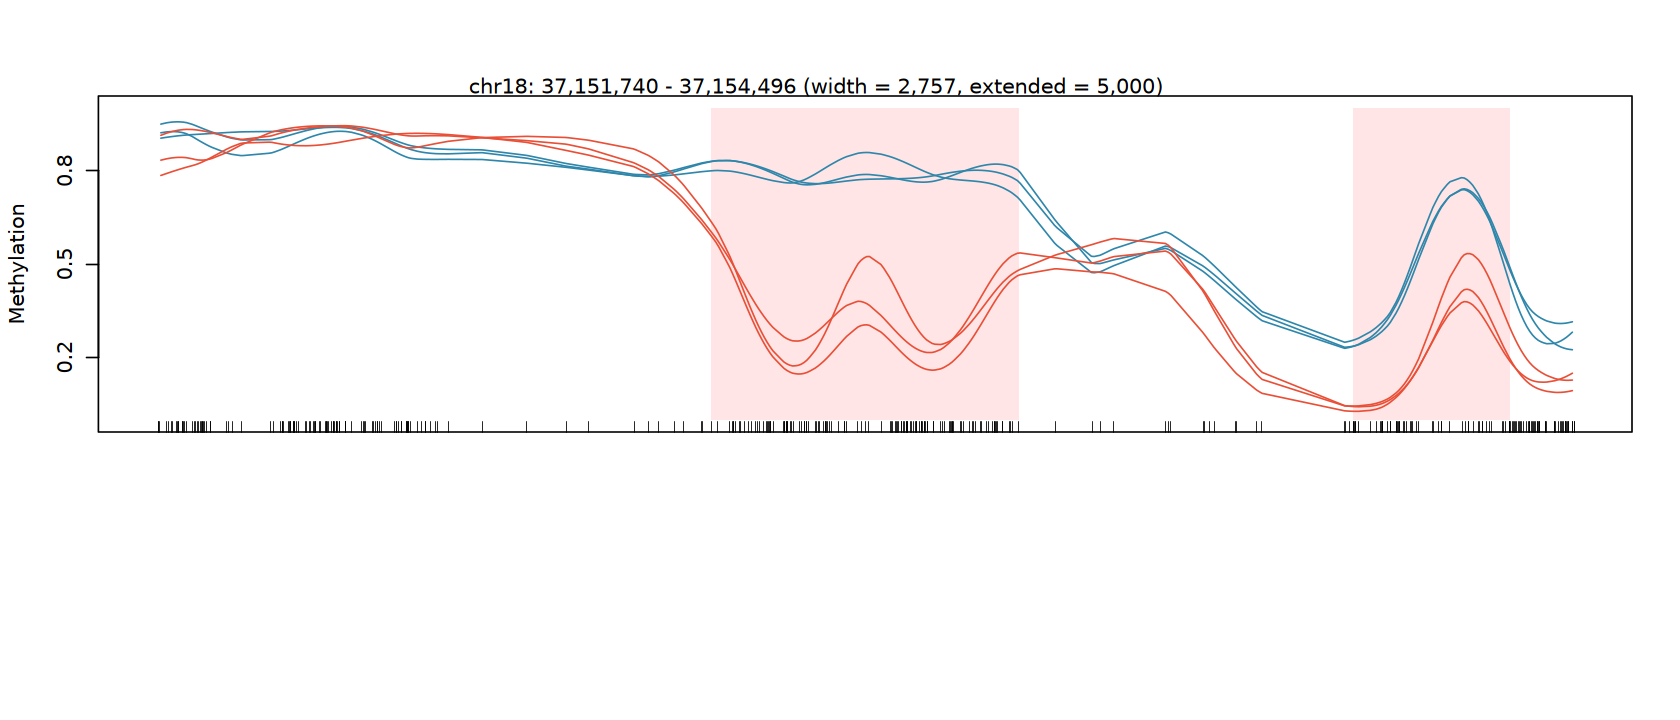

In [22]:
options(repr.plot.width = 14, repr.plot.height = 6)

plotRegion(bs_obj_fit, bsseq_dmrs[1, ], extend = 5000, addRegions = bsseq_dmrs)

# pdf(file = "bsseq_dmrs.pdf", width = 14, height = 6)
# plotManyRegions(bs_obj_fit, bsseq_dmrs, extend = 5000, addRegions = bsseq_dmrs)
# dev.off()

## 2). [DSS](https://www.bioconductor.org/packages/release/bioc/html/DSS.html)

> DSS is based on a rigorous Wald test for beta-binomial distributions
> 1. estimate mean methylation levels for all CpG site,
> 2. estimate dispersions at each CpG sites,
> 3. conduct Wald test.

In [23]:
suppressPackageStartupMessages(library(DSS))

### a). Preprocessing

In [24]:
bs_obj
coldata <- pData(bs_obj)

An object of type 'BSseq' with
  21342492 methylation loci
  6 samples
has not been smoothed
All assays are in-memory

### b). DMLs

In [25]:
# ~ 15 min
# Statistical test of differntially methylated loci
dml_test <- DMLtest(
    bs_obj, 
    group1 = rownames(coldata)[coldata$Group == "KO"], 
    group2 = rownames(coldata)[coldata$Group == "WT"], 
    smoothing = TRUE, ncores = 6)

head(dml_test)

Smoothing ...
Estimating dispersion for each CpG site, this will take a while ...
Computing test statistics ...


,chr,pos,mu1,mu2,diff,diff.se,stat,phi1,phi2,pval,fdr
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,chr1,3000574,0.6666466,0.7821273,-0.11548069,0.07097471,-1.6270680,0.05964874,0.03536295,0.10372265,0.5609459
2,chr1,3000726,0.6666466,0.7821273,-0.11548069,0.06604374,-1.7485486,0.03460319,0.03287000,0.08036907,0.5129993
3,chr1,3001346,0.7334767,0.8337452,-0.10026845,0.07889687,-1.2708799,0.04343114,0.03677300,0.20377137,0.6964599
4,chr1,3001394,0.7552161,0.8199198,-0.06470367,0.03649164,-1.7731096,0.03547384,0.03965480,0.07621055,0.5032744
5,chr1,3001631,0.7646162,0.8348786,-0.07026236,0.06901685,-1.0180464,0.02418155,0.02284232,0.30865593,0.7828051
6,chr1,3002177,0.7513469,0.7715726,-0.02022564,0.10626454,-0.1903329,0.10314982,0.29091902,0.84904824,0.9772704


In [26]:
dss_dmls <- callDML(dml_test, delta = 0.1, p.threshold = 0.01)

head(dss_dmls)

,chr,pos,mu1,mu2,diff,diff.se,stat,phi1,phi2,pval,fdr,postprob.overThreshold
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
24769,chr1,7466981,0.4856814,0.2725540,0.2131275,0.01240119,17.18605,0.04166667,0.04013719,3.377634e-66,1.168409e-61,1
28455,chr1,8288273,0.5579702,0.8534159,-0.2954457,0.01368460,-21.58966,0.04166667,0.04013719,2.246694e-103,2.893147e-98,1
31089,chr1,8929158,0.3479700,0.7253468,-0.3773768,0.02910758,-12.96490,0.04166667,0.04013719,1.934928e-38,1.727235e-34,1
46765,chr1,11609529,0.7567324,0.4578874,0.2988450,0.02374245,12.58695,0.04166667,0.04013719,2.491208e-36,1.982626e-32,1
65913,chr1,14340249,0.4018870,0.8124565,-0.4105695,0.03222586,-12.74037,0.04166667,0.04013719,3.526975e-37,2.933253e-33,1
68737,chr1,14830564,0.7210446,0.9184929,-0.1974483,0.01171886,-16.84877,0.04166667,0.04013719,1.071254e-63,3.299712e-59,1


### c). DMRs

In [27]:
# Detect differntially methylated regions
dss_dmrs <- callDMR(
    dml_test, delta = 0.1, p.threshold = 0.01, 
    minlen = 50, minCG = 3, dis.merge = 1000)

head(dss_dmrs)

,chr,start,end,length,nCG,meanMethy1,meanMethy2,diff.Methy,areaStat
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
7116,chr18,37151740,37154496,2757,124,0.3192216,0.7978648,-0.4786432,-2227.7071
7115,chr18,37132404,37135961,3558,135,0.2716009,0.6848704,-0.4132695,-2106.0571
7114,chr18,37126727,37129776,3050,125,0.3754534,0.7458491,-0.3703957,-1781.5281
7118,chr18,37157426,37159383,1958,92,0.1642262,0.4100278,-0.2458015,-883.1020
7122,chr18,37170900,37172815,1916,90,0.2477648,0.5029821,-0.2552172,-786.7759
1627,chr10,79198218,79199020,803,71,0.6034877,0.8710640,-0.2675763,-679.6404


In [28]:
# Get hyper methylated DMRs
hyper_dmrs <- dss_dmrs |> filter(nCG > 10 & diff.Methy > 0.1)
# Get hypo methylated DMRs
hypo_dmrs <- dss_dmrs |> filter(nCG > 10 & diff.Methy < -0.1)
# Get all differentially methylated DMRs
diff_dmrs <- dss_dmrs |> filter(nCG > 10)

In [29]:
message(
    "DMRs summary (DSS):\n",
    "--------------------------------\n",
    "Hyper-methylated DMRs: ", nrow(hyper_dmrs), "\n",
    "Hypo-methylated DMRs : ", nrow(hypo_dmrs), "\n",
    "Total DMRs           : ", nrow(diff_dmrs), "\n",
    "--------------------------------"
)

DMRs summary (DSS):
--------------------------------
Hyper-methylated DMRs: 154
Hypo-methylated DMRs : 239
Total DMRs           : 393
--------------------------------



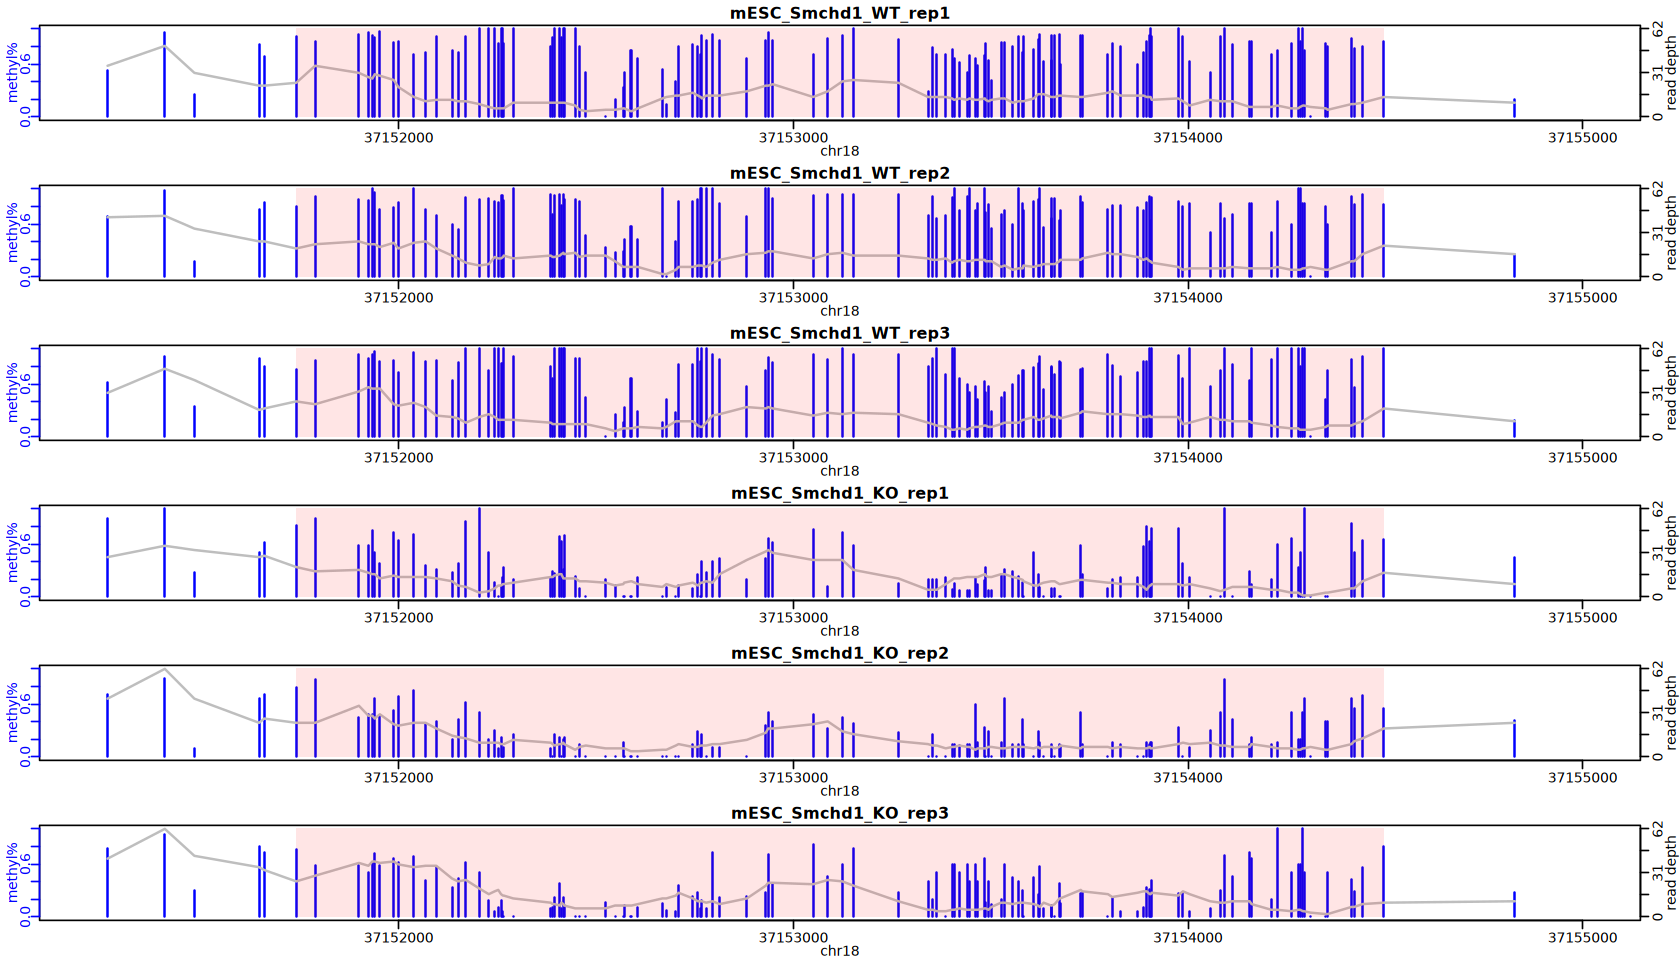

In [30]:
options(repr.plot.width = 14, repr.plot.height = 8)

showOneDMR(dss_dmrs[1, ], bs_obj)

## 3). [DMRcate](https://www.bioconductor.org/packages/release/bioc/html/DMRcate.html)

In [31]:
suppressPackageStartupMessages(library(DMRcate))
suppressPackageStartupMessages(library(DMRcatedata))

### a). Preprocessing

In [32]:
bs_obj

An object of type 'BSseq' with
  21342492 methylation loci
  6 samples
has not been smoothed
All assays are in-memory

### b). DMRs

In [33]:
# Regular matrix design
design <- model.matrix( ~ Group, data = pData(bs_obj))
colnames(design) <- gsub("Group", "", colnames(design))
colnames(design)[1] <- "Intercept"
design

# Methylation matrix design
meth_design <- edgeR::modelMatrixMeth(design)
meth_design

cont_mat <- limma::makeContrasts(KO_vs_WT = KO, levels = meth_design)
cont_mat

,Intercept,KO
mESC_Smchd1_WT_rep1,1,0
mESC_Smchd1_WT_rep2,1,0
mESC_Smchd1_WT_rep3,1,0
mESC_Smchd1_KO_rep1,1,1
mESC_Smchd1_KO_rep2,1,1
mESC_Smchd1_KO_rep3,1,1


,Sample1,Sample2,Sample3,Sample4,Sample5,Sample6,Intercept,KO
1,1,0,0,0,0,0,1,0
2,1,0,0,0,0,0,0,0
3,0,1,0,0,0,0,1,0
4,0,1,0,0,0,0,0,0
5,0,0,1,0,0,0,1,0
6,0,0,1,0,0,0,0,0
7,0,0,0,1,0,0,1,1
8,0,0,0,1,0,0,0,0
9,0,0,0,0,1,0,1,1
10,0,0,0,0,1,0,0,0


,KO_vs_WT
Sample1,0
Sample2,0
Sample3,0
Sample4,0
Sample5,0
Sample6,0
Intercept,0
KO,1


In [34]:
# ~ 5 min
# seq_anno <- sequencing.annotate(
#     bs_obj, meth_design, all.cov = TRUE, fdr = 0.05, 
#     contrasts = TRUE, cont.matrix = cont.mat, coef = "KO_vs_WT")
seq_anno <- sequencing.annotate(
    bs_obj, meth_design, all.cov = TRUE, fdr = 0.01, 
    contrasts = FALSE, coef = 8)

seq_anno <- changeFDR(seq_anno, FDR = 0.9)

seq_anno

Filtering out all CpGs where at least one sample has zero coverage...

Processing BSseq object...

Transforming counts...

Fitting model...

Warning message:
"Zero sample variances detected, have been offset away from zero"
Your contrast returned no individually significant CpGs. Consider increasing the 'fdr' parameter using changeFDR(), but be warned there is an increased risk of Type I errors.



Threshold is now set at FDR=0.9, resulting in 3434535 significantly differential CpGs.

CpGannotated object describing 18713004 CpG sites, with independent
CpG threshold indexed at fdr=0.9 and 3434535 significant CpG sites.

In [35]:
dmrcate_result <- dmrcate(seq_anno, lambda = 1000, C = 2, min.cpgs = 10)

Fitting chr1...

Fitting chr2...

Fitting chr3...

Fitting chr4...

Fitting chr5...

Fitting chr6...

Fitting chr7...

Fitting chr8...

Fitting chr9...

Fitting chr10...

Fitting chr11...

Fitting chr12...

Fitting chr13...

Fitting chr14...

Fitting chr15...

Fitting chr16...

Fitting chr17...

Fitting chr18...

Fitting chr19...

Fitting chrX...

Fitting chrY...

Demarcating regions...

Done!



In [36]:
dmrcate_result

DMResults object with 123642 DMRs.
Use extractRanges() to produce a GRanges object of these.

In [37]:
# dmrcate_dmrs <- extractRanges(result, genome = "mm9")
dmrcate_dmrs <- data.frame(
    coord = dmrcate_result@coord,
    no_cpgs = dmrcate_result@no.cpgs,
    min_smoothed_fdr = dmrcate_result@min_smoothed_fdr,
    Stouffer = dmrcate_result@Stouffer,
    HMFDR = dmrcate_result@HMFDR,
    Fisher = dmrcate_result@Fisher,
    maxdiff = dmrcate_result@maxdiff,
    meandiff = dmrcate_result@meandiff
)

head(dmrcate_dmrs)

,coord,no_cpgs,min_smoothed_fdr,Stouffer,HMFDR,Fisher,maxdiff,meandiff
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,chr18:37148596-37160779,315,0.000000e+00,1.000000e+00,0.1000488,1.376850e-267,-6.682266,-2.066159
2,chr18:37126727-37137095,282,3.653276e-312,0.000000e+00,0.1000488,0.000000e+00,-5.575224,-2.813026
3,chr18:37169559-37174119,142,4.526720e-92,1.000000e+00,0.1000488,2.103541e-49,-4.306545,-1.412472
4,chr6:4695459-4700060,170,9.104948e-73,1.757302e-40,0.1000488,3.498580e-44,-3.191810,-1.288333
5,chr18:37088295-37092603,145,1.823557e-65,3.875652e-36,0.1000488,1.298907e-38,-4.180019,-1.302686
6,chr18:37119353-37123429,150,1.536973e-49,2.411852e-35,0.1000488,1.041591e-36,-4.087759,-1.308321


In [38]:
# Get hyper methylated DMRs
hyper_dmrs <- dmrcate_dmrs |> 
    filter(no_cpgs > 10 & meandiff > 1 & Fisher < 0.01)
# Get hypo methylated DMRs
hypo_dmrs <- dmrcate_dmrs |> 
    filter(no_cpgs > 10 & meandiff < -1 & Fisher < 0.01)
# Get all differentially methylated DMRs
diff_dmrs <- dmrcate_dmrs |>
    filter(no_cpgs > 10 & Fisher < 0.01)

In [39]:
message(
    "DMRs summary (DMRcate):\n",
    "--------------------------------\n",
    "Hyper-methylated DMRs: ", nrow(hyper_dmrs), "\n",
    "Hypo-methylated DMRs : ", nrow(hypo_dmrs), "\n",
    "Total DMRs           : ", nrow(diff_dmrs), "\n",
    "--------------------------------"
)

DMRs summary (DMRcate):
--------------------------------
Hyper-methylated DMRs: 190
Hypo-methylated DMRs : 287
Total DMRs           : 4678
--------------------------------



## 4). [methylKit](https://www.bioconductor.org/packages/release/bioc/html/methylKit.html)

In [40]:
suppressPackageStartupMessages(library(methylKit))

### a). Preprocessing

In [41]:
meth_raw <- methRead(
    location = as.list(cov_files), 
    sample.id = as.list(names(cov_files)),
    treatment = c(0, 0, 0, 1, 1, 1), 
    assembly = "mm9", mincov = 5, context = "CpG", 
    pipeline = "bismarkCoverage")

Received list of locations.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.



In [42]:
getSampleID(meth_raw)
getTreatment(meth_raw)
head(meth_raw[[1]])

[1] "mESC_Smchd1_WT_rep1" "mESC_Smchd1_WT_rep2" "mESC_Smchd1_WT_rep3"
[4] "mESC_Smchd1_KO_rep1" "mESC_Smchd1_KO_rep2" "mESC_Smchd1_KO_rep3"

[1] 0 0 0 1 1 1

,chr,start,end,strand,coverage,numCs,numTs
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>
1,chr2,3000165,3000165,*,12,6,6
2,chr2,3000215,3000215,*,8,7,1
3,chr2,3000216,3000216,*,15,14,1
4,chr2,3000222,3000222,*,8,5,3
5,chr2,3000223,3000223,*,15,11,4
6,chr2,3000397,3000397,*,9,9,0


In [43]:
add_inferred_strand <- function(meth, genome) {
    infer_strand <- function(df) {
        base <- getSeq(genome, GRanges(df), as.character = TRUE)
        strand <- c(C = "+", G = "-", other = "*")
        unname(ifelse(
            base == "C", strand["C"], ifelse(
                base == "G", strand["G"], strand["other"])))
    }

    # case 1: methylRawList
    if (inherits(meth, "methylRawList")) {
        meth <- lapply(meth, function(x) {
            x$strand <- infer_strand(getData(x))
            return(x)
        }) |> 
            methylRawList(treatment = getTreatment(meth))
        return(meth)
    }

    # case 2: methylRaw / methylBase
    if (inherits(meth, "methylRaw") || inherits(meth, "methylBase")) {
        meth$strand <- infer_strand(getData(meth))
        return(meth)
    }

    stop("Unsupported methylKit object: ", paste(class(meth), collapse = ", "))
}

In [44]:
# ~ 6 min
meth_modify <- add_inferred_strand(meth_raw, genome)

In [45]:
head(meth_modify[[1]])

,chr,start,end,strand,coverage,numCs,numTs
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>
1,chr2,3000165,3000165,-,12,6,6
2,chr2,3000215,3000215,+,8,7,1
3,chr2,3000216,3000216,-,15,14,1
4,chr2,3000222,3000222,+,8,5,3
5,chr2,3000223,3000223,-,15,11,4
6,chr2,3000397,3000397,+,9,9,0


In [46]:
meth_filter <- filterByCoverage(meth_modify, lo.count = 5, hi.perc = 99.9)

In [47]:
# ~ 6 min
meth_unite <- unite(meth_filter, destrand = TRUE)

destranding...

uniting...



In [48]:
getSampleID(meth_unite)
getTreatment(meth_unite)
getData(meth_unite) |> head()

[1] "mESC_Smchd1_WT_rep1" "mESC_Smchd1_WT_rep2" "mESC_Smchd1_WT_rep3"
[4] "mESC_Smchd1_KO_rep1" "mESC_Smchd1_KO_rep2" "mESC_Smchd1_KO_rep3"

[1] 0 0 0 1 1 1

,chr,start,end,strand,coverage1,numCs1,numTs1,coverage2,numCs2,numTs2,⋯,numTs3,coverage4,numCs4,numTs4,coverage5,numCs5,numTs5,coverage6,numCs6,numTs6
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,chr1,3000574,3000574,+,23,20,3,25,19,6,⋯,5,28,26,2,30,26,4,30,23,7
2,chr1,3000726,3000726,+,5,3,2,5,3,2,⋯,4,19,9,10,17,7,10,16,7,9
3,chr1,3001346,3001346,+,15,12,3,6,5,1,⋯,1,8,7,1,13,10,3,11,11,0
4,chr1,3001394,3001394,+,16,14,2,7,6,1,⋯,1,7,6,1,16,12,4,10,10,0
5,chr1,3001631,3001631,+,49,44,5,42,36,6,⋯,8,45,36,9,51,40,11,38,33,5
6,chr1,3002177,3002177,+,32,29,3,36,35,1,⋯,3,30,29,1,36,30,6,36,29,7


In [49]:
# getCorrelation(meth_unite, method = "spearman", plot = FALSE)

In [50]:
corr_mat <- percMethylation(meth_unite) |>
    cor(method = "spearman", use = "complete.obs")

dimnames(corr_mat) <- lapply(
    dimnames(corr_mat), \(x) sub("^mESC_Smchd1_", "", x))

corr_mat

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
WT_rep1,1.0000000,0.7006367,0.6987320,0.6970646,0.7024481,0.6911995
WT_rep2,0.7006367,1.0000000,0.6933690,0.6918404,0.6973827,0.6868960
WT_rep3,0.6987320,0.6933690,1.0000000,0.6897734,0.6944823,0.6844713
KO_rep1,0.6970646,0.6918404,0.6897734,1.0000000,0.7015889,0.6874439
KO_rep2,0.7024481,0.6973827,0.6944823,0.7015889,1.0000000,0.6969213
KO_rep3,0.6911995,0.6868960,0.6844713,0.6874439,0.6969213,1.0000000


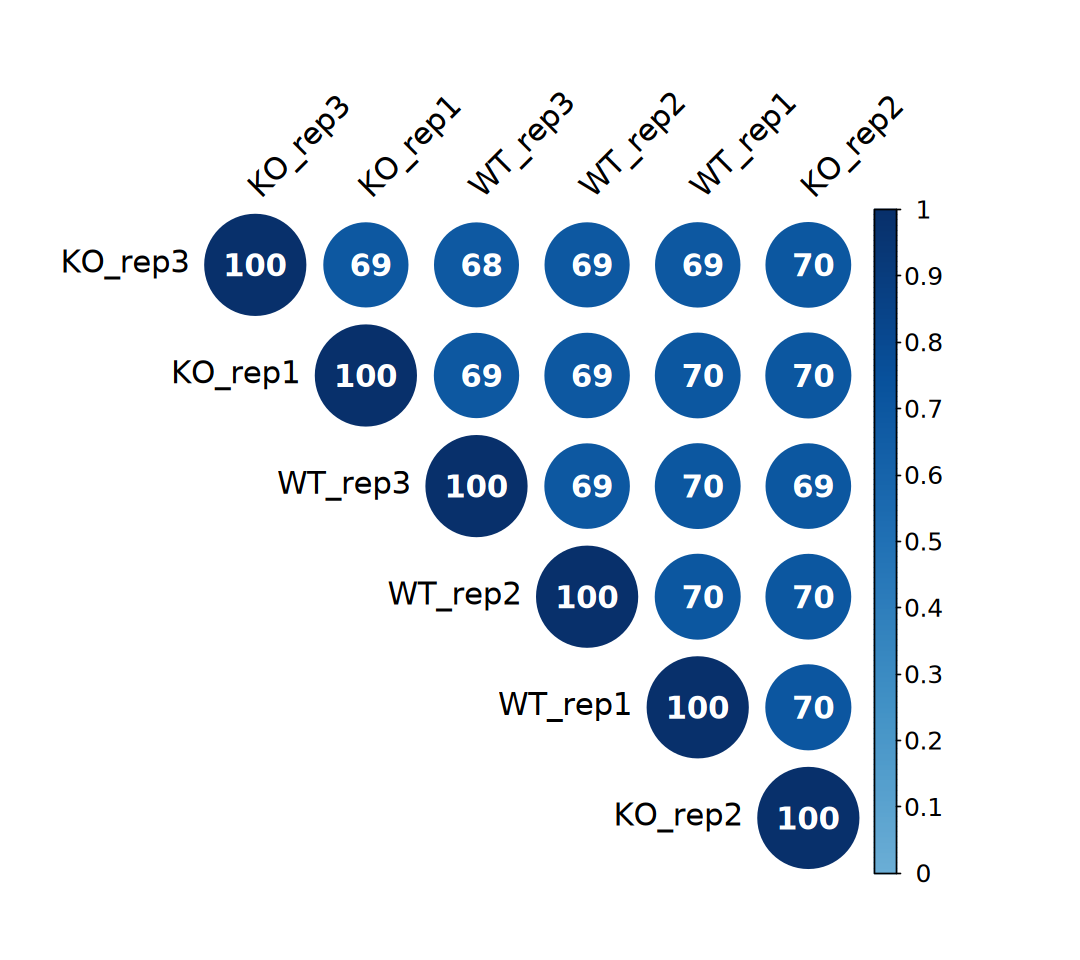

In [51]:
options(repr.plot.width = 9, repr.plot.height = 8)

corrplot::corrplot(
    corr_mat, method = "circle", type = "upper", order = "hclust", 
    col.lim = c(0, 1), col = colorRampPalette(brewer.pal(9, "Blues"))(255), 
    addgrid.col = NA, addCoef.col = "white", addCoefasPercent = TRUE,
    tl.cex = 1.5, tl.col = "black", tl.srt = 45, 
    cl.cex = 1.2, number.cex = 1.5)

### b). Tiling Windows

In [52]:
# ~ 2 min
meth_tiles <- tileMethylCounts(
    meth_unite, win.size = 1000, step.size = 500, cov.bases = 10)

In [53]:
getData(meth_tiles) |> head()

,chr,start,end,strand,coverage1,numCs1,numTs1,coverage2,numCs2,numTs2,⋯,numTs3,coverage4,numCs4,numTs4,coverage5,numCs5,numTs5,coverage6,numCs6,numTs6
,<fct>,<int>,<int>,<fct>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,chr1,3035001,3036000,*,226,194,32,234,210,24,⋯,19,216,172,44,281,221,60,216,193,23
2,chr1,3043501,3044500,*,201,148,53,161,123,38,⋯,45,126,94,32,155,104,51,214,159,55
3,chr1,3044001,3045000,*,164,139,25,159,133,26,⋯,22,138,123,15,138,121,17,119,102,17
4,chr1,3044501,3045500,*,311,265,46,334,285,49,⋯,60,329,271,58,338,289,49,336,295,41
5,chr1,3048501,3049500,*,356,291,65,343,249,94,⋯,60,299,231,68,432,336,96,376,299,77
6,chr1,3049001,3050000,*,414,348,66,383,301,82,⋯,62,303,234,69,495,397,98,412,340,72


In [54]:
# ~ 15 min
methylkit_dmrs <- calculateDiffMeth(
    meth_tiles, overdispersion = "MN", mc.cores = 1)

head(methylkit_dmrs)

two groups detected:
 will calculate methylation difference as the difference of
treatment (group: 1) - control (group: 0)



,chr,start,end,strand,pvalue,qvalue,meth.diff
,<fct>,<int>,<int>,<fct>,<dbl>,<dbl>,<dbl>
1,chr1,3035001,3036000,*,0.16045882,0.5964571,-5.9637205
2,chr1,3043501,3044500,*,0.25484004,0.6482787,-3.1064746
3,chr1,3044001,3045000,*,0.07429882,0.5220064,4.3765459
4,chr1,3044501,3045500,*,0.58555828,0.8003618,1.1743803
5,chr1,3048501,3049500,*,0.89170325,0.9140353,-0.4463057
6,chr1,3049001,3050000,*,0.68475661,0.8404331,-0.9517080


In [55]:
# Get hyper/hypo methylated DMRs
hyper_dmrs <- getMethylDiff(
    methylkit_dmrs, difference = 10, qvalue = 0.01, type = "hyper")
hypo_dmrs <- getMethylDiff(
    methylkit_dmrs, difference = 10, qvalue = 0.01, type = "hypo")
# Get all differentially methylated DMRs
diff_dmrs <- getMethylDiff(methylkit_dmrs, difference = 10, qvalue = 0.01)

In [56]:
message(
    "DMRs summary (methylKit):\n",
    "--------------------------------\n",
    "Hyper-methylated DMRs: ", nrow(hyper_dmrs), "\n",
    "Hypo-methylated DMRs : ", nrow(hypo_dmrs), "\n",
    "Total DMRs           : ", nrow(diff_dmrs), "\n",
    "--------------------------------"
)

DMRs summary (methylKit):
--------------------------------
Hyper-methylated DMRs: 251
Hypo-methylated DMRs : 310
Total DMRs           : 561
--------------------------------



### c). Predefined Regions

In [57]:
GENES <- genes(txdb)
PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

  84 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [58]:
meth_regions <- regionCounts(meth_unite, PROMOTERS)

getData(meth_regions) |> head()

,chr,start,end,strand,coverage1,numCs1,numTs1,coverage2,numCs2,numTs2,⋯,numTs3,coverage4,numCs4,numTs4,coverage5,numCs5,numTs5,coverage6,numCs6,numTs6
,<fct>,<int>,<int>,<fct>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,chr1,3661080,3663579,-,505,82,423,399,99,300,⋯,273,438,80,358,360,88,272,371,75,296
2,chr1,4398823,4401322,-,435,304,131,457,325,132,⋯,126,472,319,153,478,311,167,458,309,149
3,chr1,4485995,4488494,-,1230,167,1063,1122,191,931,⋯,1025,1037,149,888,925,152,773,1128,215,913
4,chr1,4775308,4777807,-,925,153,772,906,163,743,⋯,654,884,173,711,798,148,650,934,184,750
5,chr1,4795974,4798473,+,821,254,567,794,217,577,⋯,493,716,218,498,786,241,545,826,287,539
6,chr1,4845775,4848274,+,892,212,680,674,165,509,⋯,559,774,132,642,793,125,668,873,183,690


In [59]:
methylkit_regions <- calculateDiffMeth(
    meth_regions, overdispersion = "MN", mc.cores = 1)

head(methylkit_regions)

two groups detected:
 will calculate methylation difference as the difference of
treatment (group: 1) - control (group: 0)



,chr,start,end,strand,pvalue,qvalue,meth.diff
,<fct>,<int>,<int>,<fct>,<dbl>,<dbl>,<dbl>
1,chr1,3661080,3663579,-,0.74651640,0.8879050,1.109578
2,chr1,4398823,4401322,-,0.04688818,0.5112203,-3.546843
3,chr1,4485995,4488494,-,0.29124569,0.7194539,2.320130
4,chr1,4775308,4777807,-,0.18190828,0.6570960,1.432263
5,chr1,4795974,4798473,+,0.68394356,0.8709258,1.116403
6,chr1,4845775,4848274,+,0.07565743,0.5610849,-4.894903


In [60]:
# Get hyper/hypo methylated DMRs
hyper_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01, type = "hyper")
hypo_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01, type = "hypo")
diff_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01)

In [61]:
message(
    "Promoters summary (methylKit):\n",
    "--------------------------------\n",
    "Hyper-methylated promoters: ", nrow(hyper_regions), "\n",
    "Hypo-methylated promoters : ", nrow(hypo_regions), "\n",
    "Total promoters           : ", nrow(diff_regions), "\n",
    "--------------------------------"
)

Promoters summary (methylKit):
--------------------------------
Hyper-methylated promoters: 5
Hypo-methylated promoters : 5
Total promoters           : 10
--------------------------------



## 5). [methylSig](https://www.bioconductor.org/packages/release/bioc/html/methylSig.html)

In [62]:
# suppressPackageStartupMessages(library(methylSig))

## 6). [dmrseq](https://www.bioconductor.org/packages/release/bioc/html/dmrseq.html)

In [63]:
# suppressPackageStartupMessages(library(dmrseq))

# * Reference